# Part 2: Dynamic Correlation (DCC-GARCH) vs. Static Correlation

### Ramith Vaid | NTU Singapore

The README's own "Known Limitations" section flags it: *"The GARCH-informed covariance matrix updates each asset's individual volatility dynamically but reuses the static historical correlation matrix. A fuller dynamic conditional correlation model (DCC-GARCH) would let correlations shift too."* This notebook adds a simple DCC estimate and compares it head-to-head against the static correlation used so far.

**The DCC model** (Engle 2002, in its simplest two-parameter form, implemented in `portfolio_utils.py`): fit GARCH(1,1) per asset exactly as before, standardize each asset's returns by its own conditional volatility, then let the correlation matrix evolve as `Q_t = (1-a-b) Qbar + a z_{t-1} z_{t-1}' + b Q_{t-1}` with `a`, `b` shared by every pair, estimated by maximizing the correlation part of the Gaussian quasi-likelihood (the standard two-step estimator). To forecast, the correlation matrix is mean-reverted from today's `Q` toward `Qbar` and averaged over the 126-day test horizon.

**The comparison is a one-variable change.** The DCC covariance uses *exactly the same* per-asset GARCH volatilities as Part 1's "GARCH-informed" covariance; the only difference is the correlation matrix (DCC forecast vs. static historical). So any difference in results is attributable to the correlation model alone.

Two head-to-head tests, both on the same 15 rolling windows as Part 1 (5-year train, 6-month test):

1. **Correlation forecast accuracy**, independent of any portfolio: how far is each method's correlation matrix from the correlations actually realized in the next 6 months (mean absolute error over the 28 pairwise correlations)?
2. **Portfolio volatility prediction error**, the Part 1 metric: for the Max Sharpe portfolio chosen under each covariance, |predicted vol - realized vol| in the test window. Plain sample covariance and the Part 1 static-correlation GARCH covariance are included as reference points.

**Data end date is pinned** (`END = '2026-10-14'`, exclusive, so the last row is 2026-10-13, the same last row Part 1 used) so this notebook reproduces rather than drifting with a live download.

In [1]:
import pandas as pd
import numpy as np
import yfinance as yf
import matplotlib.pyplot as plt
import warnings
warnings.filterwarnings('ignore')

from portfolio_utils import (
    portfolio_variance, max_sharpe_portfolio, build_garch_covariance, build_dcc_covariance,
    run_rolling_dcc_comparison
)

print('Libraries loaded.')

Libraries loaded.


## 1. Data Collection (same universe and range as Part 1, end date pinned)

In [2]:
TICKERS = {
    'JPM':  'Financials',
    'AAPL': 'Technology',
    'XOM':  'Energy',
    'JNJ':  'Healthcare',
    'PG':   'Consumer Staples',
    'CAT':  'Industrials',
    'NEE':  'Utilities',
    'AMZN': 'Consumer Discretionary',
}
START = '2014-01-01'
END = '2026-10-14'  # exclusive: last row is 2026-10-13, matching the Part 1 run
tickers = list(TICKERS.keys())
n_assets = len(tickers)

prices = {}
for ticker, sector in TICKERS.items():
    df = yf.download(ticker, start=START, end=END, progress=False)
    prices[ticker] = df['Close'].squeeze()

price_df = pd.DataFrame(prices).dropna()
log_returns = np.log(price_df / price_df.shift(1)).dropna()
print(f'{price_df.shape[0]} trading days, {price_df.shape[1]} assets '
      f'({price_df.index[0].date()} to {price_df.index[-1].date()})')

3214 trading days, 8 assets (2014-01-02 to 2026-10-13)


## 2. Full-sample DCC fit

Fit the DCC model on the full history. `a + b` is the persistence of correlation shocks: close to 1 means correlation changes slowly but is genuinely time-varying; `a` near 0 would mean the static matrix was already fine.

In [3]:
ANNUALIZE = 252
cov_static, vols_static = build_garch_covariance(log_returns, tickers)
cov_dcc, vols_dcc, info = build_dcc_covariance(log_returns, tickers, horizon_days=126)

print(f'DCC parameters: a = {info["a"]:.4f}, b = {info["b"]:.4f}, persistence a + b = {info["a"] + info["b"]:.4f}')
print(f'Same GARCH volatilities in both covariances (isolation check): {np.allclose(vols_static.values, vols_dcc.values)}')

mask = ~np.eye(n_assets, dtype=bool)
R_static = log_returns.corr().values
avg_corr_static = R_static[mask].mean()
avg_corr_path = pd.Series([R[mask].mean() for R in info['R_path']], index=log_returns.index)
avg_corr_forecast = info['R_forecast'][mask].mean()

print()
print(f'Average pairwise correlation, static (full-sample historical): {avg_corr_static:.3f}')
print(f'Average pairwise correlation, DCC over time: min {avg_corr_path.min():.3f} ({avg_corr_path.idxmin().date()}), '
      f'max {avg_corr_path.max():.3f} ({avg_corr_path.idxmax().date()}), last {avg_corr_path.iloc[-1]:.3f}')
print(f'Average pairwise correlation, DCC forecast over the next 126 days: {avg_corr_forecast:.3f}')

DCC parameters: a = 0.0095, b = 0.9815, persistence a + b = 0.9910
Same GARCH volatilities in both covariances (isolation check): True

Average pairwise correlation, static (full-sample historical): 0.324
Average pairwise correlation, DCC over time: min 0.143 (2026-08-03), max 0.464 (2020-04-07), last 0.164
Average pairwise correlation, DCC forecast over the next 126 days: 0.199


## 3. Full-sample Max Sharpe: static vs. DCC correlation

Same method as before (35% position cap, same GARCH volatilities), changing only the correlation matrix.

In [4]:
mean_returns = log_returns.mean() * ANNUALIZE
w_static = max_sharpe_portfolio(mean_returns, cov_static, n_assets)
w_dcc = max_sharpe_portfolio(mean_returns, cov_dcc, n_assets)
vol_static = np.sqrt(portfolio_variance(w_static, cov_static.values))
vol_dcc = np.sqrt(portfolio_variance(w_dcc, cov_dcc.values))

print('Max Sharpe weights and predicted volatility (GARCH volatilities; correlation differs):')
print(f'{"Ticker":<8} {"Static corr":>12} {"DCC corr":>10}')
for t, ws, wd in zip(tickers, w_static, w_dcc):
    print(f'{t:<8} {ws*100:>11.1f}% {wd*100:>9.1f}%')
print(f'\nPredicted volatility: static {vol_static*100:.2f}%, DCC {vol_dcc*100:.2f}%')

Max Sharpe weights and predicted volatility (GARCH volatilities; correlation differs):
Ticker    Static corr   DCC corr
JPM             35.0%      29.1%
AAPL            35.0%      35.0%
XOM              0.0%       0.0%
JNJ              3.6%       7.1%
PG               0.0%       0.0%
CAT              0.0%       3.5%
NEE             23.5%      21.1%
AMZN             2.9%       4.2%

Predicted volatility: static 14.48%, DCC 13.18%


## 4. Rolling out-of-sample head-to-head

Each window: fit everything on the 5 years of training data only, then compare to what happened in the next 6 months. Each window fits 8 univariate GARCH models and one DCC model, so this takes a few minutes.

In [5]:
windows, res = run_rolling_dcc_comparison(log_returns, tickers, n_assets, annualize=ANNUALIZE,
                                            train_years=5, test_months=6)
persistence = res['dcc_a'] + res['dcc_b']
print(f'\n{len(windows)} windows. DCC persistence a + b across windows: min {persistence.min():.3f}, max {persistence.max():.3f} (must stay below 1 for the correlation process to be stationary)')
assert persistence.max() < 1, 'DCC fit left the stationary region'

Running 15 rolling windows: sample vs. GARCH+static corr vs. GARCH+DCC corr...



  Window 1/15 (test starting 2019-01-07): sample=3.56%, static=7.27%, dcc=6.83%  |  corr err static=0.129, dcc=0.109  (a=0.016, b=0.838)


  Window 2/15 (test starting 2019-07-09): sample=3.63%, static=0.88%, dcc=0.68%  |  corr err static=0.169, dcc=0.166  (a=0.020, b=0.799)


  Window 3/15 (test starting 2020-01-07): sample=29.49%, static=33.04%, dcc=33.66%  |  corr err static=0.339, dcc=0.376  (a=0.021, b=0.828)


  Window 4/15 (test starting 2020-07-08): sample=3.48%, static=0.99%, dcc=2.87%  |  corr err static=0.231, dcc=0.182  (a=0.025, b=0.868)


...

  Window 11/15 (test starting 2024-01-09): sample=9.37%, static=4.03%, dcc=2.68%  |  corr err static=0.263, dcc=0.178  (a=0.012, b=0.966)


  Window 12/15 (test starting 2024-07-11): sample=8.42%, static=4.04%, dcc=2.83%  |  corr err static=0.312, dcc=0.209  (a=0.012, b=0.968)


  Window 13/15 (test starting 2025-01-10): sample=5.44%, static=12.25%, dcc=12.53%  |  corr err static=0.175, dcc=0.161  (a=0.010, b=0.974)


  Window 14/15 (test starting 2025-07-15): sample=6.43%, static=5.18%, dcc=5.14%  |  corr err static=0.182, dcc=0.167  (a=0.009, b=0.979)


  Window 15/15 (test starting 2026-01-13): sample=3.06%, static=2.42%, dcc=1.53%  |  corr err static=0.183, dcc=0.155  (a=0.010, b=0.970)

15 windows. DCC persistence a + b across windows: min 0.819, max 0.988 (must stay below 1 for the correlation process to be stationary)


### 4a. Correlation forecast accuracy

Mean absolute error between each method's correlation matrix and the correlations realized in the test window (lower is better).

In [6]:
d_corr = res['corr_err_static'] - res['corr_err_dcc']  # positive = DCC closer to realized
t_corr = d_corr.mean() / (d_corr.std(ddof=1) / np.sqrt(len(d_corr)))
print(f'Mean correlation error across {len(res)} windows:')
print(f'  Static historical correlation: {res["corr_err_static"].mean():.4f}')
print(f'  DCC forecast:                  {res["corr_err_dcc"].mean():.4f}')
print(f'  DCC closer to realized correlations in {(d_corr > 0).sum()} of {len(res)} windows; '
      f'mean improvement {d_corr.mean():+.4f} (paired t-statistic {t_corr:+.2f}, n = {len(res)}).')
print()
print(res[['window', 'test_start', 'corr_err_static', 'corr_err_dcc', 'dcc_a', 'dcc_b']].to_string(index=False))

Mean correlation error across 15 windows:
  Static historical correlation: 0.2082
  DCC forecast:                  0.1683
  DCC closer to realized correlations in 12 of 15 windows; mean improvement +0.0399 (paired t-statistic +3.14, n = 15).

 window test_start  corr_err_static  corr_err_dcc    dcc_a    dcc_b
      1 2019-01-07         0.128761      0.109318 0.016211 0.838331
      2 2019-07-09         0.169092      0.166481 0.020327 0.799171
      3 2020-01-07         0.338976      0.376203 0.020883 0.828317
      4 2020-07-08         0.231218      0.181907 0.024846 0.868338
      5 2021-01-06         0.268660      0.177593 0.017584 0.926495
      6 2021-07-08         0.184894      0.090864 0.013388 0.959893
      7 2022-01-05         0.152814      0.157196 0.013233 0.963513
      8 2022-07-08         0.101460      0.139781 0.015900 0.959351
      9 2023-01-06         0.170337      0.095785 0.014557 0.964398
     10 2023-07-11         0.261228      0.159954 0.011600 0.968142
     11 2

### 4b. Portfolio volatility prediction error

The Part 1 metric. As in Part 1, the window with the largest sample-covariance error (the COVID crash window) is also reported excluded, so the numbers are comparable to the Part 1 table.

In [7]:
METHODS = [('sample', 'Sample covariance'), ('garch_static', 'GARCH + static corr (Part 1)'), ('garch_dcc', 'GARCH + DCC corr (Part 2)')]
outlier_idx = res['sample_error'].idxmax()
print(f'Largest sample-covariance error: window {res.loc[outlier_idx, "window"]}, test starting {res.loc[outlier_idx, "test_start"]}')
print()

def summarize(frame, label):
    print(f'{label} ({len(frame)} windows): average |predicted - realized| portfolio volatility')
    for key, name in METHODS:
        print(f'  {name:<32} {frame[key + "_error"].mean()*100:6.2f}%  (std {frame[key + "_error"].std()*100:.2f}%)')
    d = frame['garch_static_error'] - frame['garch_dcc_error']  # positive = DCC better
    print(f'  DCC lower error than static in {(d > 0).sum()} of {len(frame)} windows; '
          f'mean difference {d.mean()*100:+.2f} pp (paired t-statistic {d.mean() / (d.std(ddof=1) / np.sqrt(len(d))):+.2f})')
    print()

summarize(res, 'All windows')
summarize(res.drop(outlier_idx), 'Excluding the largest-error window')

print('Per-window prediction error (%):')
show = res[['window', 'test_start'] + [k + '_error' for k, _ in METHODS]].copy()
for k, _ in METHODS:
    show[k + '_error'] = show[k + '_error'] * 100
print(show.to_string(index=False, float_format=lambda v: f'{v:.2f}'))

Largest sample-covariance error: window 3, test starting 2020-01-07

All windows (15 windows): average |predicted - realized| portfolio volatility
  Sample covariance                  7.36%  (std 6.66%)
  GARCH + static corr (Part 1)       6.23%  (std 8.29%)
  GARCH + DCC corr (Part 2)          5.91%  (std 8.63%)
  DCC lower error than static in 10 of 15 windows; mean difference +0.32 pp (paired t-statistic +1.09)

Excluding the largest-error window (14 windows): average |predicted - realized| portfolio volatility
  Sample covariance                  5.78%  (std 2.71%)
  GARCH + static corr (Part 1)       4.32%  (std 3.84%)
  GARCH + DCC corr (Part 2)          3.92%  (std 4.08%)
  DCC lower error than static in 10 of 14 windows; mean difference +0.39 pp (paired t-statistic +1.26)

Per-window prediction error (%):
 window test_start  sample_error  garch_static_error  garch_dcc_error
      1 2019-01-07          3.56                7.27             6.83
      2 2019-07-09          3.63   

## 5. Chart: DCC correlation over time, and per-window correlation forecast error

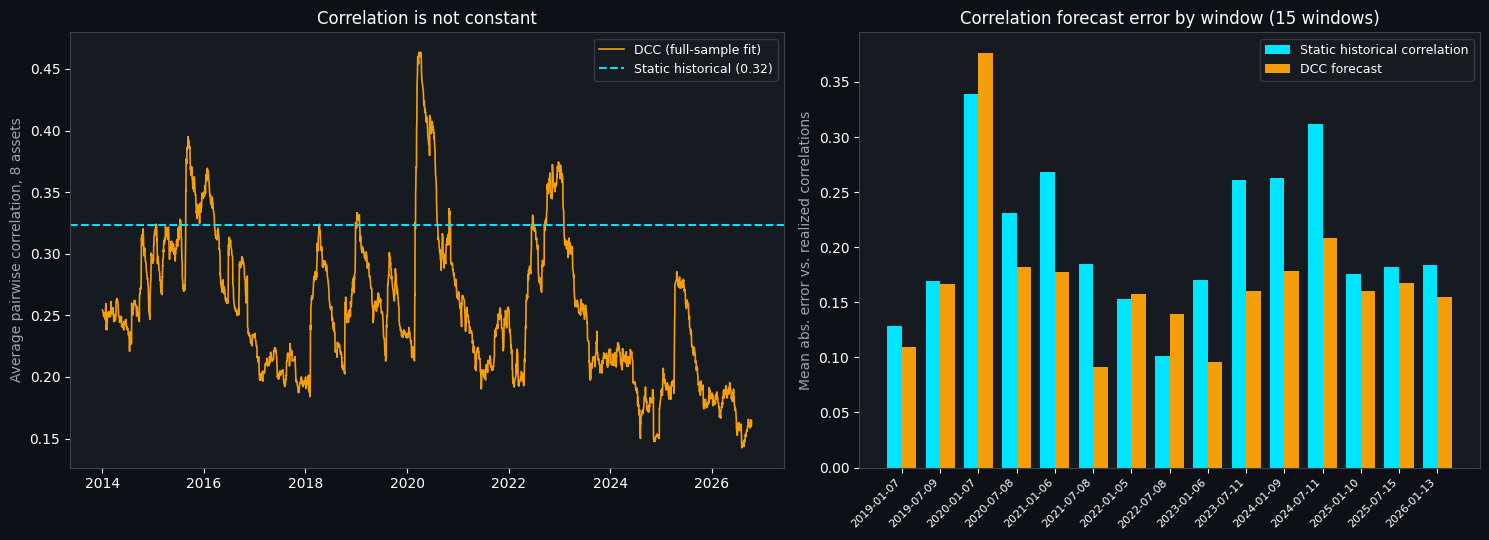

Saved chart_part2_dcc.png


In [8]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5.5), gridspec_kw={'width_ratios': [1.15, 1]})
fig.patch.set_facecolor('#0d1117')
for ax in axes:
    ax.set_facecolor('#161b22')
    ax.tick_params(colors='white')
    for spine in ax.spines.values():
        spine.set_edgecolor('#374151')

ax = axes[0]
ax.plot(avg_corr_path.index, avg_corr_path.values, color='#f59e0b', linewidth=1.2, label='DCC (full-sample fit)')
ax.axhline(avg_corr_static, color='#00e5ff', linestyle='--', linewidth=1.5, label=f'Static historical ({avg_corr_static:.2f})')
ax.set_ylabel('Average pairwise correlation, 8 assets', color='#9ca3af')
ax.set_title('Correlation is not constant', color='white', fontsize=12)
ax.legend(facecolor='#161b22', edgecolor='#374151', labelcolor='white', fontsize=9)

ax = axes[1]
x = np.arange(len(res))
width = 0.38
ax.bar(x - width/2, res['corr_err_static'], width, color='#00e5ff', label='Static historical correlation')
ax.bar(x + width/2, res['corr_err_dcc'], width, color='#f59e0b', label='DCC forecast')
ax.set_xticks(x)
ax.set_xticklabels([str(d) for d in res['test_start']], color='white', rotation=45, ha='right', fontsize=8)
ax.set_ylabel('Mean abs. error vs. realized correlations', color='#9ca3af')
ax.set_title(f'Correlation forecast error by window ({len(res)} windows)', color='white', fontsize=12)
ax.legend(facecolor='#161b22', edgecolor='#374151', labelcolor='white', fontsize=9)

plt.tight_layout()
plt.savefig('chart_part2_dcc.png', dpi=150, bbox_inches='tight', facecolor='#0d1117')
plt.show()
print('Saved chart_part2_dcc.png')

## 6. Summary

In [9]:
res.to_csv('part2_rolling_dcc_comparison.csv', index=False)
res_ex = res.drop(outlier_idx)
d_all = res['garch_static_error'] - res['garch_dcc_error']
d_ex = res_ex['garch_static_error'] - res_ex['garch_dcc_error']

print('=' * 70)
print('PART 2 SUMMARY: DCC vs. STATIC CORRELATION')
print('=' * 70)
print(f'Data: {price_df.index[0].date()} to {price_df.index[-1].date()} ({price_df.shape[0]} trading days), {len(res)} rolling windows')
print(f'Full-sample DCC: a = {info["a"]:.4f}, b = {info["b"]:.4f}, persistence {info["a"] + info["b"]:.4f}; '
      f'average pairwise correlation ranges {avg_corr_path.min():.2f} to {avg_corr_path.max():.2f} (static: {avg_corr_static:.2f})')
print()
print('Correlation forecast error (mean abs. error vs. realized):')
print(f'  static {res["corr_err_static"].mean():.4f}, DCC {res["corr_err_dcc"].mean():.4f}; '
      f'DCC closer in {(d_corr > 0).sum()} of {len(res)} windows')
print()
print('Portfolio volatility prediction error:')
for key, name in METHODS:
    print(f'  {name:<32} all windows {res[key + "_error"].mean()*100:5.2f}%   excl. largest {res_ex[key + "_error"].mean()*100:5.2f}%')
print(f'  DCC beats static GARCH in {(d_all > 0).sum()} of {len(res)} windows ({(d_ex > 0).sum()} of {len(res_ex)} excluding the largest-error window)')
print()
print('Files saved: chart_part2_dcc.png, part2_rolling_dcc_comparison.csv')

PART 2 SUMMARY: DCC vs. STATIC CORRELATION
Data: 2014-01-02 to 2026-10-13 (3214 trading days), 15 rolling windows
Full-sample DCC: a = 0.0095, b = 0.9815, persistence 0.9910; average pairwise correlation ranges 0.14 to 0.46 (static: 0.32)

Correlation forecast error (mean abs. error vs. realized):
  static 0.2082, DCC 0.1683; DCC closer in 12 of 15 windows

Portfolio volatility prediction error:
  Sample covariance                all windows  7.36%   excl. largest  5.78%
  GARCH + static corr (Part 1)     all windows  6.23%   excl. largest  4.32%
  GARCH + DCC corr (Part 2)        all windows  5.91%   excl. largest  3.92%
  DCC beats static GARCH in 10 of 15 windows (10 of 14 excluding the largest-error window)

Files saved: chart_part2_dcc.png, part2_rolling_dcc_comparison.csv
